<a href="https://colab.research.google.com/github/nurulfdlharba-dotcom/rf-dengan-threshold/blob/Hasil1%2Bthreshold/hasil_1_rf_baru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Import library

In [3]:
# 1. Library untuk pengolahan data dan numerik
import pandas as pd
import numpy as np

# 2. Library untuk visualisasi data dan grafik evaluasi
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Library untuk pembagian data dan 5-Fold Cross-Validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# 4. Library algoritma Random Forest
from sklearn.ensemble import RandomForestClassifier

# 5. Library lengkap untuk evaluasi performa model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 6. Library untuk menyimpan model
import joblib

print("Semua library berhasil di-import!")

Semua library berhasil di-import!


# 2. Load dataset

In [4]:
# Membaca dataset dari file CSV
df = pd.read_csv('dataset1.csv')

# Menampilkan ukuran dataset (jumlah baris, jumlah kolom)
print("Ukuran dataset (baris, kolom):", df.shape)

# Menampilkan 5 baris pertama untuk memastikan data terbaca dengan benar
print("\n5 baris pertama dataset:")
display(df.head())

Ukuran dataset (baris, kolom): (880, 13)

5 baris pertama dataset:


,N,P,K,pH,EC,OC,S,Zn,Fe,Cu,Mn,B,Output
0,138,8.6,560,7.46,0.62,0.70,5.9,0.24,0.31,0.77,8.71,0.11,0
1,213,7.5,338,7.62,0.75,1.06,25.4,0.30,0.86,1.54,2.89,2.29,0
2,163,9.6,718,7.59,0.51,1.11,14.3,0.30,0.86,1.57,2.70,2.03,0
3,157,6.8,475,7.64,0.58,0.94,26.0,0.34,0.54,1.53,2.65,1.82,0
4,270,9.9,444,7.63,0.40,0.86,11.8,0.25,0.76,1.69,2.43,2.26,1


# 3. Cleaning dataset

In [5]:
# 1. Memilih hanya 5 kolom parameter yang akan digunakan
kolom_pilihan = ['N', 'P', 'K', 'pH', 'EC']
df_clean = df[kolom_pilihan].copy()

# 2. Cek dan hapus data kosong (missing values) jika ada
print("Jumlah missing values sebelum cleaning:\n", df_clean.isnull().sum())
df_clean = df_clean.dropna()

# 3. Cek dan hapus data duplikat
print("\nJumlah baris duplikat sebelum cleaning:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# 4. Hapus nilai yang tidak masuk akal secara fisik (nilai negatif atau pH di luar 0-14)
df_clean = df_clean[
    (df_clean['N'] >= 0) &
    (df_clean['P'] >= 0) &
    (df_clean['K'] >= 0) &
    (df_clean['EC'] >= 0) &
    (df_clean['pH'] >= 0) & (df_clean['pH'] <= 14)
].reset_index(drop=True)

# 5. Menyamakan satuan EC dari dS/m ke µS/cm (dikali 1000) agar sesuai dengan threshold
df_clean['EC'] = df_clean['EC'] * 1000

print("\nUkuran dataset setelah cleaning (baris, kolom):", df_clean.shape)
display(df_clean.head())

Jumlah missing values sebelum cleaning:
 N     0
P     0
K     0
pH    0
EC    0
dtype: int64

Jumlah baris duplikat sebelum cleaning: 16

Ukuran dataset setelah cleaning (baris, kolom): (864, 5)


,N,P,K,pH,EC
0,138,8.6,560,7.46,620.0
1,213,7.5,338,7.62,750.0
2,163,9.6,718,7.59,510.0
3,157,6.8,475,7.64,580.0
4,270,9.9,444,7.63,400.0


# 4. EDA (Exploratory Data Analysis)

In [8]:
# 1. Ringkasan Statistik Deskriptif (Mean, Std, Min, Kuartil, Max)
print("Ringkasan Statistik Deskriptif:")
display(df_clean.describe().round(2))

# Daftar parameter dan warna agar grafik rapi
fitur = ['N', 'P', 'K', 'pH', 'EC']
warna = ['#2b5c8f', '#388e3c', '#f57c00', '#7b1fa2', '#00838f']

Ringkasan Statistik Deskriptif:


,N,P,K,pH,EC
count,864.00,864.00,864.00,864.00,864.00
mean,245.50,14.61,501.05,7.51,543.29
std,77.45,22.16,124.75,0.47,141.81
min,6.00,2.90,11.00,0.90,100.00
25%,201.00,6.80,412.00,7.35,430.00
50%,257.00,8.10,475.00,7.50,545.00
75%,302.50,10.50,581.00,7.63,640.00
max,383.00,125.00,887.00,11.15,950.00


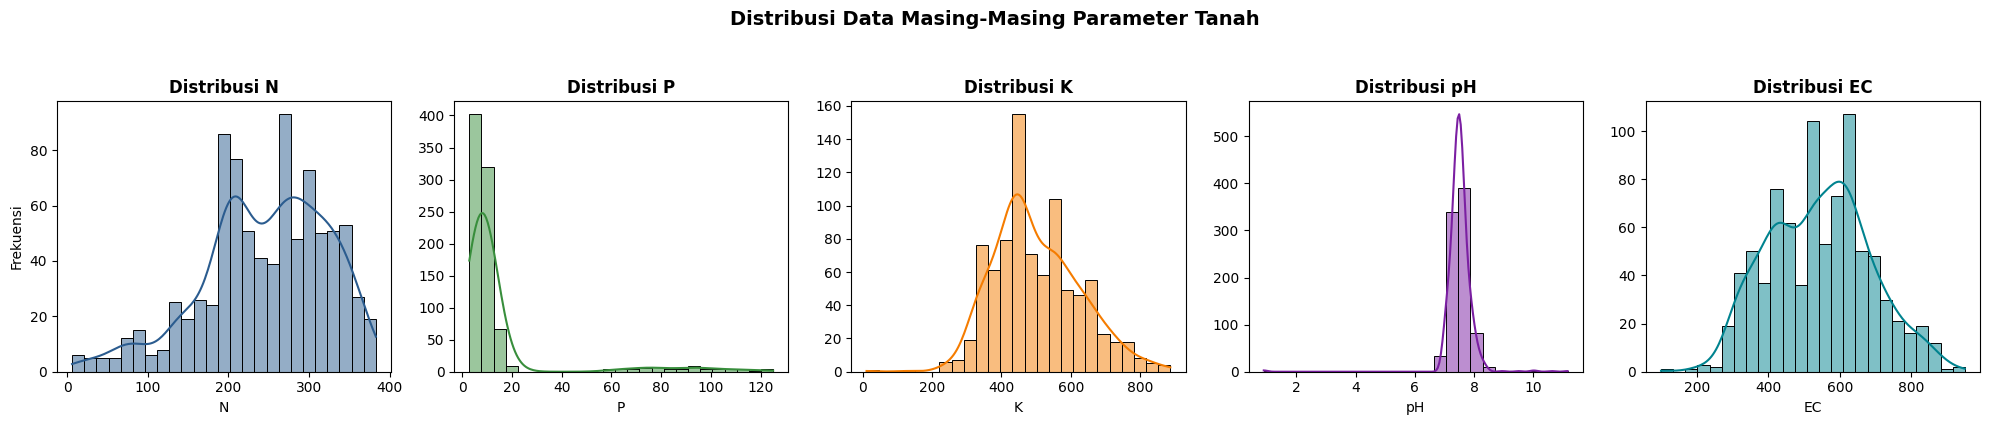

In [9]:
# 2. Visualisasi Distribusi Data (Histogram + KDE)
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, col in enumerate(fitur):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color=warna[i], bins=25)
    axes[i].set_title(f'Distribusi {col}', fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi' if i == 0 else '')
plt.suptitle('Distribusi Data Masing-Masing Parameter Tanah', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

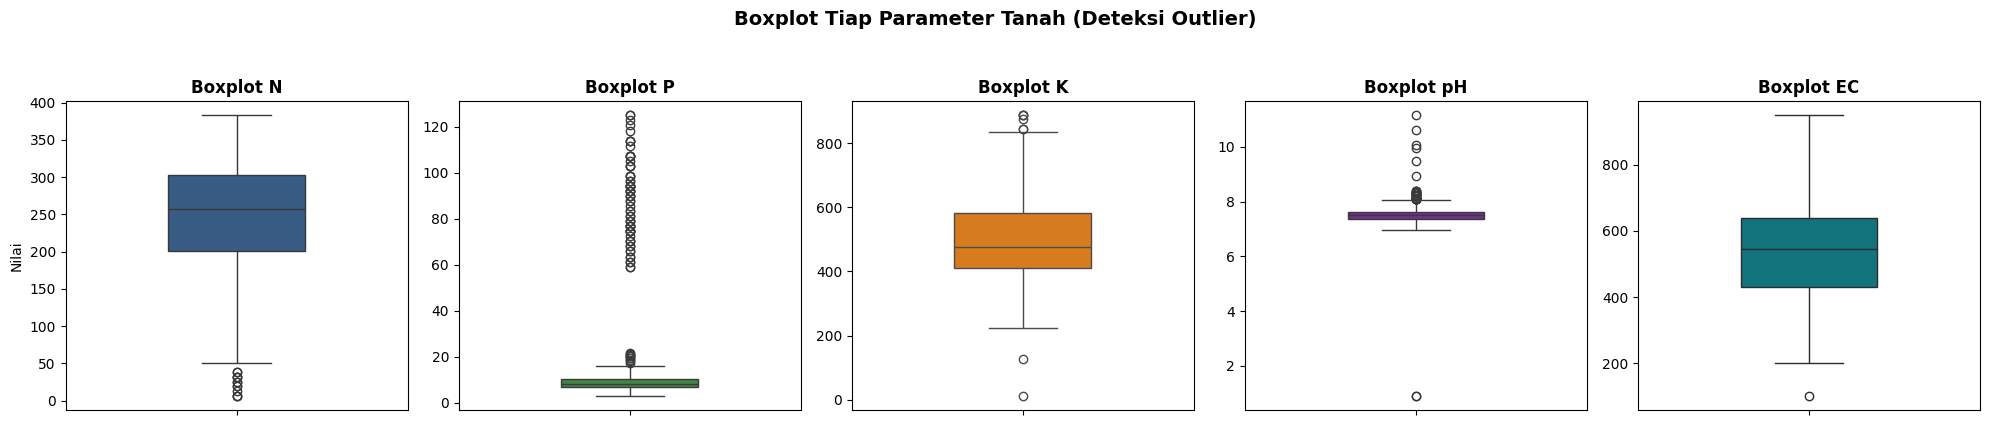

In [10]:
# 3. Visualisasi Boxplot (Deteksi Sebaran & Outlier)
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, col in enumerate(fitur):
    sns.boxplot(y=df_clean[col], ax=axes[i], color=warna[i], width=0.4)
    axes[i].set_title(f'Boxplot {col}', fontweight='bold')
    axes[i].set_ylabel('Nilai' if i == 0 else '')
plt.suptitle('Boxplot Tiap Parameter Tanah (Deteksi Outlier)', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

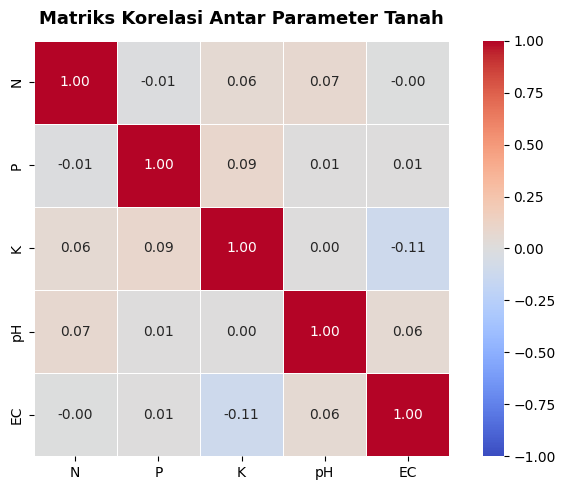

In [11]:
# 4. Visualisasi Korelasi Antar Parameter (Heatmap)
plt.figure(figsize=(7, 5))
korelasi = df_clean.corr()
sns.heatmap(
    korelasi,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)
plt.title('Matriks Korelasi Antar Parameter Tanah', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# 5. Data Augmentation dan pelabelan target

In [12]:
# Fungsi pemberian skor (0-4) sesuai tabel threshold Anda
def skor_N(x):
    if x < 100: return 0
    elif x < 160: return 1
    elif x <= 240: return 2
    elif x <= 300: return 3
    else: return 4

def skor_P(x):
    if x < 150: return 0
    elif x < 240: return 1
    elif x <= 360: return 2
    elif x <= 450: return 3
    else: return 4

def skor_K(x):
    if x < 250: return 0
    elif x < 400: return 1
    elif x <= 600: return 2
    elif x <= 750: return 3
    else: return 4

def skor_pH(x):
    if x < 5.8: return 0
    elif x < 6.3: return 1
    elif x <= 7.3: return 2
    elif x <= 7.8: return 3
    else: return 4

def skor_EC(x):
    if x < 350: return 0
    elif x < 560: return 1
    elif x <= 840: return 2
    elif x <= 1050: return 3
    else: return 4

# Fungsi menghitung label akhir dari rata-rata skor ke-5 parameter (dibulatkan ke 0-4)
def hitung_label(df_input):
    s_n = df_input['N'].apply(skor_N)
    s_p = df_input['P'].apply(skor_P)
    s_k = df_input['K'].apply(skor_K)
    s_ph = df_input['pH'].apply(skor_pH)
    s_ec = df_input['EC'].apply(skor_EC)

    rata2 = (s_n + s_p + s_k + s_ph + s_ec) / 5.0
    return np.floor(rata2 + 0.5).astype(int)

# Cek label sementara pada data asli (df_clean)
label_asli = hitung_label(df_clean)
print("Distribusi kelas pada data asli (sebelum augmentasi):")
print(label_asli.value_counts().sort_index())

Distribusi kelas pada data asli (sebelum augmentasi):
1    153
2    703
3      8
Name: count, dtype: int64


In [13]:
np.random.seed(42)

# Rentang nilai tiap tingkatan (0-4) berdasarkan tabel threshold
rentang_param = {
    'N':  [(20, 99), (100, 159), (160, 240), (241, 300), (301, 420)],
    'P':  [(10, 149), (150, 239), (240, 360), (361, 450), (451, 600)],
    'K':  [(50, 249), (250, 399), (400, 600), (601, 750), (751, 950)],
    'pH': [(4.5, 5.79), (5.8, 6.29), (6.3, 7.3), (7.31, 7.8), (7.81, 8.8)],
    'EC': [(100, 349), (350, 559), (560, 840), (841, 1050), (1051, 1350)]
}

def buat_sampel_kelas(target_kelas, jumlah):
    data_list = []
    while len(data_list) < jumlah:
        # Variasi skor tiap parameter (-1, 0, atau +1 dari target) agar kombinasi realistis
        level_acak = np.clip(target_kelas + np.random.choice([-1, 0, 0, 1], size=5), 0, 4)
        baris = {}
        for idx, param in enumerate(['N', 'P', 'K', 'pH', 'EC']):
            batas_bawah, batas_atas = rentang_param[param][level_acak[idx]]
            if param in ['N', 'K']:
                baris[param] = int(np.random.randint(batas_bawah, batas_atas + 1))
            elif param == 'pH':
                baris[param] = round(float(np.random.uniform(batas_bawah, batas_atas)), 2)
            else:
                baris[param] = round(float(np.random.uniform(batas_bawah, batas_atas)), 1)

        # Simpan jika hasil perhitungan label sesuai dengan target_kelas
        if hitung_label(pd.DataFrame([baris])).iloc[0] == target_kelas:
            data_list.append(baris)
    return pd.DataFrame(data_list)

# Menyeimbangkan setiap kelas menjadi 700 data
target_per_kelas = 700
jumlah_awal = label_asli.value_counts().to_dict()

kumpulan_sintetis = []
for kelas in range(5):
    kekurangan = max(0, target_per_kelas - jumlah_awal.get(kelas, 0))
    if kekurangan > 0:
        kumpulan_sintetis.append(buat_sampel_kelas(kelas, kekurangan))

df_sintetis = pd.concat(kumpulan_sintetis, ignore_index=True)
print("Jumlah data sintetis yang berhasil dibuat:", df_sintetis.shape)

Jumlah data sintetis yang berhasil dibuat: (2639, 5)


Ukuran dataset final (baris, kolom): (3503, 6)

Distribusi final ke-5 kelas:
Label
0 (Sangat Rendah)    700
1 (Rendah)           700
2 (Sedang)           703
3 (Tinggi)           700
4 (Sangat Tinggi)    700
Name: count, dtype: int64


/tmp/ipykernel_1173/4074224543.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Label', data=df_final, palette='viridis')


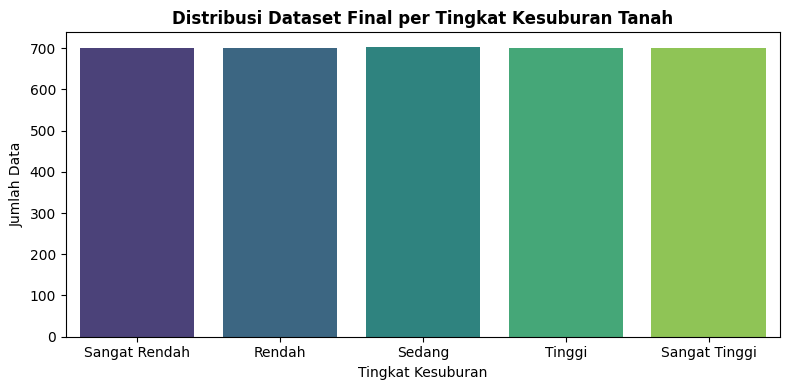

,N,P,K,pH,EC,Label
0,352,475.3,735,7.49,1242.8,4
1,370,11.8,686,7.50,610.0,2
2,399,410.3,539,6.71,705.3,3
3,257,297.6,882,7.78,1043.5,3
4,320,7.5,433,7.46,700.0,2


In [14]:
# Menggabungkan data asli dan data sintetis
df_final = pd.concat([df_clean[['N', 'P', 'K', 'pH', 'EC']], df_sintetis], ignore_index=True)

# Memberikan kolom Label target akhir (0 sampai 4)
df_final['Label'] = hitung_label(df_final)

# Memastikan tidak ada duplikat dan mengacak urutan baris
df_final = df_final.drop_duplicates().sample(frac=1, random_state=42).reset_index(drop=True)

print("Ukuran dataset final (baris, kolom):", df_final.shape)
print("\nDistribusi final ke-5 kelas:")
nama_kelas = {0: '0 (Sangat Rendah)', 1: '1 (Rendah)', 2: '2 (Sedang)', 3: '3 (Tinggi)', 4: '4 (Sangat Tinggi)'}
print(df_final['Label'].map(nama_kelas).value_counts().sort_index())

# Visualisasi distribusi kelas final
plt.figure(figsize=(8, 4))
sns.countplot(x='Label', data=df_final, palette='viridis')
plt.xticks(ticks=[0, 1, 2, 3, 4], labels=['Sangat Rendah', 'Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi'])
plt.title('Distribusi Dataset Final per Tingkat Kesuburan Tanah', fontweight='bold')
plt.xlabel('Tingkat Kesuburan')
plt.ylabel('Jumlah Data')
plt.tight_layout()
plt.show()

display(df_final.head())

# 6. Pemisahan Fitur (x), Target (y), dan Train-Test Split

In [15]:
# 1. Memisahkan variabel fitur (X) dan target (y)
X = df_final[['N', 'P', 'K', 'pH', 'EC']]
y = df_final['Label']

# 2. Membagi data: 80% Latih (Train) dan 20% Uji (Test) secara berstrata
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Ukuran X_train (80%):", X_train.shape)
print("Ukuran X_test  (20%):", X_test.shape)

print("\nProporsi kelas pada y_train:")
print(y_train.value_counts().sort_index())

print("\nProporsi kelas pada y_test:")
print(y_test.value_counts().sort_index())

Ukuran X_train (80%): (2802, 5)
Ukuran X_test  (20%): (701, 5)

Proporsi kelas pada y_train:
Label
0    560
1    560
2    562
3    560
4    560
Name: count, dtype: int64

Proporsi kelas pada y_test:
Label
0    140
1    140
2    141
3    140
4    140
Name: count, dtype: int64


In [16]:
# 1. Inisialisasi model Random Forest untuk Cross-Validation
rf_cv = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Konfigurasi Stratified 5-Fold Cross-Validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 3. Menghitung skor akurasi di setiap fold pada data latih (X_train, y_train)
cv_scores = cross_val_score(rf_cv, X_train, y_train, cv=skf, scoring='accuracy')

# 4. Menampilkan hasil per fold, rata-rata, dan standar deviasi
for fold, skor in enumerate(cv_scores, start=1):
    print(f"Fold {fold}: Akurasi = {skor * 100:.2f}%")

print(f"\nRata-rata Akurasi 5-Fold CV : {cv_scores.mean() * 100:.2f}%")
print(f"Standar Deviasi (Stabilitas): ±{cv_scores.std() * 100:.2f}%")

Fold 1: Akurasi = 96.79%
Fold 2: Akurasi = 97.33%
Fold 3: Akurasi = 97.68%
Fold 4: Akurasi = 96.43%
Fold 5: Akurasi = 98.75%

Rata-rata Akurasi 5-Fold CV : 97.39%
Standar Deviasi (Stabilitas): ±0.80%


# 7. Pelatihan Model (Model Training) & Evaluasi

In [18]:
# 1. Inisialisasi model Random Forest final
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# 2. Melatih model menggunakan keseluruhan 80% data latih
rf_model.fit(X_train, y_train)

print("Pelatihan model Random Forest final selesai!")

Pelatihan model Random Forest final selesai!


In [19]:
# Melakukan prediksi pada 20% data uji (X_test)
y_pred = rf_model.predict(X_test)

print("Prediksi pada data uji selesai!")
print("Jumlah data uji yang diprediksi:", len(y_pred))

Prediksi pada data uji selesai!
Jumlah data uji yang diprediksi: 701


In [20]:
# Daftar nama label untuk memudahkan pembacaan laporan
nama_kelas = ['Sangat Rendah', 'Rendah', 'Sedang', 'Tinggi', 'Sangat Tinggi']

# 1. Menghitung metrik evaluasi keseluruhan (Macro Average)
akurasi   = accuracy_score(y_test, y_pred)
presisi   = precision_score(y_test, y_pred, average='macro')
recall    = recall_score(y_test, y_pred, average='macro')
f1        = f1_score(y_test, y_pred, average='macro')

print("=== RINGKASAN EVALUASI MODEL PADA DATA UJI (20%) ===")
print(f"Accuracy  : {akurasi * 100:.2f}%")
print(f"Precision : {presisi * 100:.2f}%")
print(f"Recall    : {recall * 100:.2f}%")
print(f"F1-Score  : {f1 * 100:.2f}%")

# 2. Menampilkan Classification Report lengkap per kelas
print("\n=== CLASSIFICATION REPORT PER KELAS ===")
print(classification_report(y_test, y_pred, target_names=nama_kelas))

=== RINGKASAN EVALUASI MODEL PADA DATA UJI (20%) ===
Accuracy  : 97.72%
Precision : 97.75%
Recall    : 97.72%
F1-Score  : 97.71%

=== CLASSIFICATION REPORT PER KELAS ===
               precision    recall  f1-score   support

Sangat Rendah       0.99      1.00      0.99       140
       Rendah       0.99      0.94      0.96       140
       Sedang       0.95      0.99      0.97       141
       Tinggi       0.99      0.97      0.98       140
Sangat Tinggi       0.98      0.99      0.98       140

     accuracy                           0.98       701
    macro avg       0.98      0.98      0.98       701
 weighted avg       0.98      0.98      0.98       701



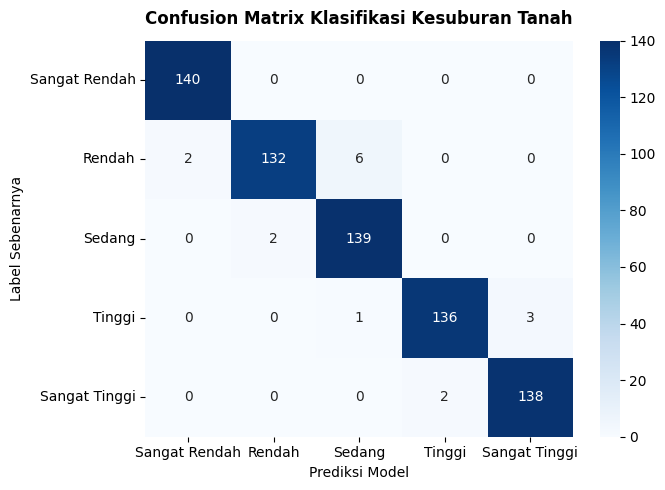

In [22]:
plt.figure(figsize=(7, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=nama_kelas,
    yticklabels=nama_kelas
)
plt.title('Confusion Matrix Klasifikasi Kesuburan Tanah', fontweight='bold', pad=12)
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()

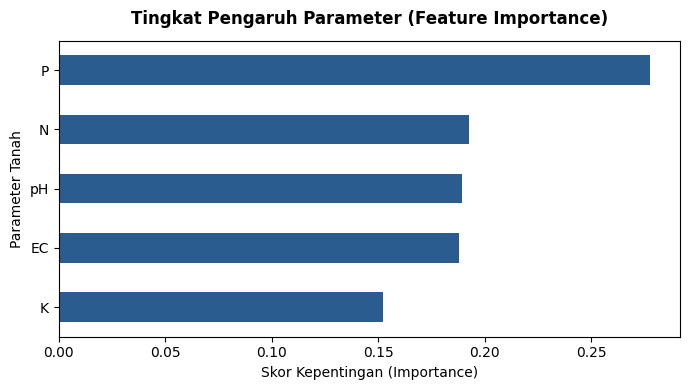

In [23]:
plt.figure(figsize=(7, 4))
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)
importances.plot(kind='barh', color='#2b5c8f')
plt.title('Tingkat Pengaruh Parameter (Feature Importance)', fontweight='bold', pad=12)
plt.xlabel('Skor Kepentingan (Importance)')
plt.ylabel('Parameter Tanah')
plt.tight_layout()
plt.show()

# 8. Hyperparameter tuning

In [24]:
from sklearn.model_selection import GridSearchCV

# 1. Menentukan daftar kandidat hyperparameter yang akan diuji
param_grid = {
    'n_estimators': [50, 100, 150, 200],
    'max_depth': [None, 10, 15, 20],
    'min_samples_split': [2, 5, 10]
}

# 2. Konfigurasi Stratified 5-Fold CV & GridSearchCV
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=skf,
    scoring='accuracy',
    n_jobs=-1
)

# 3. Menjalankan proses pencarian pada 80% data latih
grid_search.fit(X_train, y_train)

print("=== HASIL HYPERPARAMETER TUNING (GRIDSEARCHCV) ===")
print("Kombinasi Parameter Terbaik :", grid_search.best_params_)
print(f"Skor Rata-rata 5-Fold CV    : {grid_search.best_score_ * 100:.2f}%")

=== HASIL HYPERPARAMETER TUNING (GRIDSEARCHCV) ===
Kombinasi Parameter Terbaik : {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
Skor Rata-rata 5-Fold CV    : 97.61%


In [25]:
# 1. Mengambil model dengan parameter terbaik dari hasil GridSearchCV
best_rf = grid_search.best_estimator_

# 2. Melakukan prediksi pada 20% data uji (X_test)
y_pred_tuned = best_rf.predict(X_test)

# 3. Menghitung metrik evaluasi setelah tuning
akurasi_tuned = accuracy_score(y_test, y_pred_tuned)
presisi_tuned = precision_score(y_test, y_pred_tuned, average='macro')
recall_tuned  = recall_score(y_test, y_pred_tuned, average='macro')
f1_tuned      = f1_score(y_test, y_pred_tuned, average='macro')

print("=== EVALUASI MODEL SETELAH TUNING (DATA UJI 20%) ===")
print(f"Accuracy  : {akurasi_tuned * 100:.2f}%")
print(f"Precision : {presisi_tuned * 100:.2f}%")
print(f"Recall    : {recall_tuned * 100:.2f}%")
print(f"F1-Score  : {f1_tuned * 100:.2f}%")

print("\n=== CLASSIFICATION REPORT (SETELAH TUNING) ===")
print(classification_report(y_test, y_pred_tuned, target_names=nama_kelas))

=== EVALUASI MODEL SETELAH TUNING (DATA UJI 20%) ===
Accuracy  : 97.57%
Precision : 97.61%
Recall    : 97.57%
F1-Score  : 97.57%

=== CLASSIFICATION REPORT (SETELAH TUNING) ===
               precision    recall  f1-score   support

Sangat Rendah       0.99      1.00      0.99       140
       Rendah       0.98      0.94      0.96       140
       Sedang       0.95      0.99      0.97       141
       Tinggi       0.99      0.97      0.98       140
Sangat Tinggi       0.98      0.99      0.98       140

     accuracy                           0.98       701
    macro avg       0.98      0.98      0.98       701
 weighted avg       0.98      0.98      0.98       701



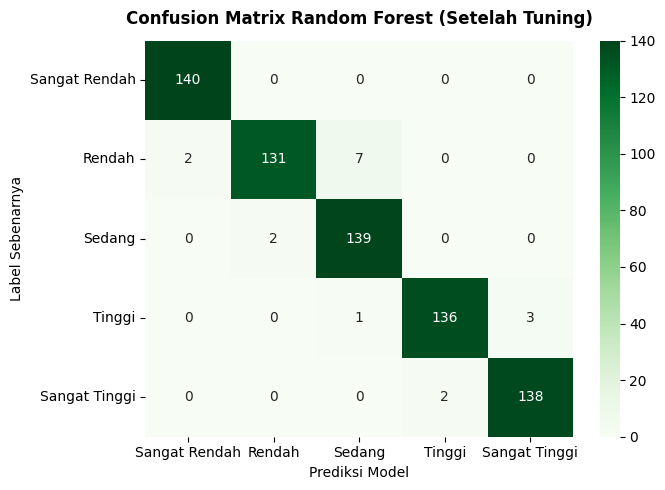

In [26]:
plt.figure(figsize=(7, 5))
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(
    cm_tuned,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=nama_kelas,
    yticklabels=nama_kelas
)
plt.title('Confusion Matrix Random Forest (Setelah Tuning)', fontweight='bold', pad=12)
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()

=== TINGKAT PENGARUH PARAMETER (SETELAH TUNING) ===
P   : 27.48%
N   : 19.27%
EC  : 19.07%
pH  : 18.81%
K   : 15.38%


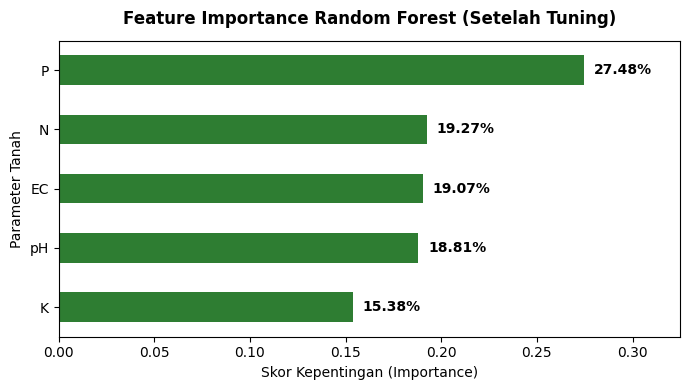

In [27]:
# 1. Menghitung skor Feature Importance dari model terbaik (best_rf)
importances_tuned = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=True)

# 2. Menampilkan rincian skor dalam bentuk persentase
print("=== TINGKAT PENGARUH PARAMETER (SETELAH TUNING) ===")
for param, skor in importances_tuned.sort_values(ascending=False).items():
    print(f"{param:<4}: {skor * 100:.2f}%")

# 3. Visualisasi grafik batang horizontal
plt.figure(figsize=(7, 4))
ax = importances_tuned.plot(kind='barh', color='#2e7d32')
plt.title('Feature Importance Random Forest (Setelah Tuning)', fontweight='bold', pad=12)
plt.xlabel('Skor Kepentingan (Importance)')
plt.ylabel('Parameter Tanah')
plt.xlim(0, importances_tuned.max() + 0.05)

# Menambahkan label angka di ujung setiap batang
for i, v in enumerate(importances_tuned):
    ax.text(v + 0.005, i, f"{v * 100:.2f}%", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

# 9. Uji coba prediksi data baru

In [28]:
# 1. Membuat 5 contoh data pengukuran sensor baru (urutan kolom wajib: N, P, K, pH, EC)
data_sensor_baru = pd.DataFrame([
    {'N': 75,  'P': 40,  'K': 180, 'pH': 5.4, 'EC': 250},   # Simulasi 1: Sangat Rendah
    {'N': 130, 'P': 15,  'K': 320, 'pH': 6.0, 'EC': 450},   # Simulasi 2: Rendah
    {'N': 220, 'P': 12,  'K': 480, 'pH': 7.4, 'EC': 600},   # Simulasi 3: Sedang
    {'N': 270, 'P': 380, 'K': 650, 'pH': 7.5, 'EC': 900},   # Simulasi 4: Tinggi
    {'N': 350, 'P': 500, 'K': 820, 'pH': 8.1, 'EC': 1150}   # Simulasi 5: Sangat Tinggi
])

# 2. Melakukan prediksi kelas dan probabilitas langsung menggunakan best_rf
prediksi_angka = best_rf.predict(data_sensor_baru)
probabilitas   = best_rf.predict_proba(data_sensor_baru)

# 3. Menyusun hasil prediksi ke dalam tabel yang mudah dibaca
hasil_uji = data_sensor_baru.copy()
hasil_uji['Prediksi_Kelas'] = [nama_kelas[i] for i in prediksi_angka]
hasil_uji['Keyakinan (%)']  = np.round(probabilitas.max(axis=1) * 100, 2)

print("=== HASIL UJI COBA PREDIKSI DATA BARU ===")
display(hasil_uji)

=== HASIL UJI COBA PREDIKSI DATA BARU ===


,N,P,K,pH,EC,Prediksi_Kelas,Keyakinan (%)
0,75,40,180,5.4,250,Sangat Rendah,100.0
1,130,15,320,6.0,450,Rendah,95.8
2,220,12,480,7.4,600,Sedang,99.5
3,270,380,650,7.5,900,Tinggi,100.0
4,350,500,820,8.1,1150,Sangat Tinggi,100.0


# 10. Pengujian & Pemilihan Model yang Sesuai

In [31]:
import time

# Daftar kandidat model: dari full (best_rf) hingga versi ringan khusus ESP32
kandidat_esp32 = {
    'Model_1_Full_100_Pohon': best_rf,
    'Model_2_Medium_50_Pohon': RandomForestClassifier(n_estimators=50, max_depth=12, min_samples_split=5, random_state=42).fit(X_train, y_train),
    'Model_3_Ringan_30_Pohon': RandomForestClassifier(n_estimators=30, max_depth=10, min_samples_split=5, random_state=42).fit(X_train, y_train),
    'Model_4_UltraRingan_20_Pohon': RandomForestClassifier(n_estimators=20, max_depth=8, min_samples_split=5, random_state=42).fit(X_train, y_train)
}

hasil_uji_esp32 = []

for nama, model in kandidat_esp32.items():
    # 1. Uji akurasi pada 20% data uji
    mulai = time.time()
    pred = model.predict(X_test)
    waktu_ms = ((time.time() - mulai) / len(X_test)) * 1000

    akurasi = accuracy_score(y_test, pred) * 100

    # 2. Hitung total node (cabang keputusan) & estimasi ukuran kode C++ (KB)
    total_nodes = sum(est.tree_.node_count for est in model.estimators_)
    estimasi_kb = (total_nodes * 45) / 1024  # Rata-rata ~45 byte per baris if-else C++

    hasil_uji_esp32.append({
        'Kandidat Model': nama,
        'Akurasi Uji (%)': round(akurasi, 2),
        'Total Node': total_nodes,
        'Estimasi Ukuran C++ (KB)': round(estimasi_kb, 1),
        'Waktu/Sampel (ms)': round(waktu_ms, 4)
    })

df_komparasi = pd.DataFrame(hasil_uji_esp32)
print("=== HASIL PENGUJIAN MODEL UNTUK DEPLOYMENT ESP32 ===")
display(df_komparasi)

=== HASIL PENGUJIAN MODEL UNTUK DEPLOYMENT ESP32 ===


,Kandidat Model,Akurasi Uji (%),Total Node,Estimasi Ukuran C++ (KB),Waktu/Sampel (ms)
0,Model_1_Full_100_Pohon,97.57,24474,1075.5,0.0809
1,Model_2_Medium_50_Pohon,97.29,12024,528.4,0.0295
2,Model_3_Ringan_30_Pohon,97.43,6784,298.1,0.0133
3,Model_4_UltraRingan_20_Pohon,96.86,3488,153.3,0.0095


In [30]:
import time

# Kandidat model khusus memori terbatas (Nano & Micro ESP32)
kandidat_nano = {
    'Nano_1_15Pohon_Depth7': RandomForestClassifier(n_estimators=15, max_depth=7, min_samples_leaf=5, random_state=42).fit(X_train, y_train),
    'Nano_2_10Pohon_Depth7': RandomForestClassifier(n_estimators=10, max_depth=7, min_samples_leaf=5, random_state=42).fit(X_train, y_train),
    'Nano_3_10Pohon_Depth6': RandomForestClassifier(n_estimators=10, max_depth=6, min_samples_leaf=8, random_state=42).fit(X_train, y_train),
    'Nano_4_5Pohon_Depth6':  RandomForestClassifier(n_estimators=5,  max_depth=6, min_samples_leaf=8, random_state=42).fit(X_train, y_train),
    'Nano_5_5Pohon_Depth5':  RandomForestClassifier(n_estimators=5,  max_depth=5, min_samples_leaf=10, random_state=42).fit(X_train, y_train)
}

hasil_nano = []

for nama, model in kandidat_nano.items():
    mulai = time.time()
    pred = model.predict(X_test)
    waktu_ms = ((time.time() - mulai) / len(X_test)) * 1000

    akurasi = accuracy_score(y_test, pred) * 100
    total_nodes = sum(est.tree_.node_count for est in model.estimators_)
    estimasi_kb = (total_nodes * 45) / 1024

    hasil_nano.append({
        'Kandidat Model': nama,
        'Akurasi Uji (%)': round(akurasi, 2),
        'Total Node': total_nodes,
        'Estimasi Ukuran C++ (KB)': round(estimasi_kb, 1),
        'Waktu/Sampel (ms)': round(waktu_ms, 4)
    })

df_nano = pd.DataFrame(hasil_nano)
print("=== HASIL PENGUJIAN MODEL NANO / MICRO UNTUK ESP32 ===")
display(df_nano)

=== HASIL PENGUJIAN MODEL NANO / MICRO UNTUK ESP32 ===


,Kandidat Model,Akurasi Uji (%),Total Node,Estimasi Ukuran C++ (KB),Waktu/Sampel (ms)
0,Nano_1_15Pohon_Depth7,96.29,1835,80.6,0.0080
1,Nano_2_10Pohon_Depth7,96.29,1230,54.1,0.0063
2,Nano_3_10Pohon_Depth6,95.29,858,37.7,0.0059
3,Nano_4_5Pohon_Depth6,93.58,413,18.1,0.0046
4,Nano_5_5Pohon_Depth5,94.72,261,11.5,0.0112


In [33]:
import os
from sklearn.tree import _tree

# 1. Mengambil model terpilih (Nano_2_10Pohon_Depth7)
model_esp32 = kandidat_nano['Nano_2_10Pohon_Depth7']
fitur_nama  = ['N', 'P', 'K', 'pH', 'EC']
jumlah_kelas = 5

# 2. Fungsi untuk mengonversi setiap pohon keputusan menjadi fungsi C++
def tree_to_cpp(tree, tree_index, feature_names):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    lines = [f"int predict_tree_{tree_index}(float N, float P, float K, float pH, float EC) {{"]

    def recurse(node, depth):
        indent = "    " * depth
        if tree_.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            lines.append(f"{indent}if ({name} <= {threshold:.4f}f) {{")
            recurse(tree_.children_left[node], depth + 1)
            lines.append(f"{indent}}} else {{")
            recurse(tree_.children_right[node], depth + 1)
            lines.append(f"{indent}}}")
        else:
            kelas_leaf = int(np.argmax(tree_.value[node][0]))
            lines.append(f"{indent}return {kelas_leaf};")

    recurse(0, 1)
    lines.append("}\n")
    return "\n".join(lines)

# 3. Menyusun seluruh kode C++ ke dalam file header (.h)
cpp_code = [
    "#ifndef MODEL_KESUBURAN_TANAH_H",
    "#define MODEL_KESUBURAN_TANAH_H",
    "",
    "// Model Random Forest (10 Pohon, Max Depth 7) untuk ESP32",
    "// Urutan Input: N, P, K, pH, EC (dalam uS/cm)",
    "// Output Kelas: 0=Sangat Rendah, 1=Rendah, 2=Sedang, 3=Tinggi, 4=Sangat Tinggi",
    ""
]

# Tambahkan kode ke-10 pohon
for idx, estimator in enumerate(model_esp32.estimators_):
    cpp_code.append(tree_to_cpp(estimator, idx, fitur_nama))

# Tambahkan fungsi utama voting (mayoritas suara dari 10 pohon)
cpp_code.append("int predict_kesuburan_tanah(float N, float P, float K, float pH, float EC) {")
cpp_code.append(f"    int votes[{jumlah_kelas}] = {{0, 0, 0, 0, 0}};")
for idx in range(len(model_esp32.estimators_)):
    cpp_code.append(f"    votes[predict_tree_{idx}(N, P, K, pH, EC)]++;")
cpp_code.append("")
cpp_code.append("    int best_class = 0;")
cpp_code.append("    int max_votes = votes[0];")
cpp_code.append(f"    for (int i = 1; i < {jumlah_kelas}; i++) {{")
cpp_code.append("        if (votes[i] > max_votes) {")
cpp_code.append("            max_votes = votes[i];")
cpp_code.append("            best_class = i;")
cpp_code.append("        }")
cpp_code.append("    }")
cpp_code.append("    return best_class;")
cpp_code.append("}")
cpp_code.append("")
cpp_code.append("#endif // MODEL_KESUBURAN_TANAH_H")

# 4. Simpan menjadi file .h
nama_file_h = "model_kesuburan_tanah.h"
with open(nama_file_h, "w") as f:
    f.write("\n".join(cpp_code))

ukuran_aktual_kb = os.path.getsize(nama_file_h) / 1024
print(f"Berhasil mengekspor model ke file C++: {nama_file_h}")
print(f"Ukuran file aktual: {ukuran_aktual_kb:.2f} KB")

Berhasil mengekspor model ke file C++: model_kesuburan_tanah.h
Ukuran file aktual: 84.09 KB


In [34]:
# Uji 5 sampel simulasi pada model_esp32 yang baru diekspor
data_uji_esp = pd.DataFrame([
    {'N': 75,  'P': 40,  'K': 180, 'pH': 5.4, 'EC': 250},   # Sangat Rendah (0)
    {'N': 130, 'P': 15,  'K': 320, 'pH': 6.0, 'EC': 450},   # Rendah (1)
    {'N': 220, 'P': 12,  'K': 480, 'pH': 7.4, 'EC': 600},   # Sedang (2)
    {'N': 270, 'P': 380, 'K': 650, 'pH': 7.5, 'EC': 900},   # Tinggi (3)
    {'N': 350, 'P': 500, 'K': 820, 'pH': 8.1, 'EC': 1150}   # Sangat Tinggi (4)
])

pred_esp = model_esp32.predict(data_uji_esp)
hasil_esp = data_uji_esp.copy()
hasil_esp['Prediksi_Angka'] = pred_esp
hasil_esp['Tingkat_Kesuburan'] = [nama_kelas[i] for i in pred_esp]

print("=== VERIFIKASI PREDIKSI MODEL ESP32 ===")
display(hasil_esp)

=== VERIFIKASI PREDIKSI MODEL ESP32 ===


,N,P,K,pH,EC,Prediksi_Angka,Tingkat_Kesuburan
0,75,40,180,5.4,250,0,Sangat Rendah
1,130,15,320,6.0,450,1,Rendah
2,220,12,480,7.4,600,2,Sedang
3,270,380,650,7.5,900,3,Tinggi
4,350,500,820,8.1,1150,4,Sangat Tinggi


In [35]:
from google.colab import files

# Mengunduh file header C++ ke komputer lokal
files.download('model_kesuburan_tanah.h')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>